# Física Nuclear e de Partículas
## Exercicio de avaliación continua: análise de datos simulados. Desintegracións tauónicas

# Solucións.
## 0. Preámbulo
Primeiras liñas de código

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple

In [5]:
## NOTA: ¡Modifica la variable *datadir* para que apunte al directorio de tu ordenador donde has guardado el fichero de datos,
## y cambia XX por el número de tu grupo!
datadir  = "."
datafile = "/taus_grupo_03.csv"
data     = pd.read_csv(datadir + datafile)

In [6]:
Particle = namedtuple('Particle', ('x', 'p', 'E', "name"))

def event_particles(data, event_number):
    dpars = data[data.event == event_number] ## get the particles of the same event
    npars = len(dpars) ## number of particles in the event
    pars  = [Particle(np.array((dpars.x.values[i] , dpars.y.values[i] , dpars.z.values[i])), 
                      np.array((dpars.px.values[i], dpars.py.values[i], dpars.pz.values[i])),
                      dpars.E.values[i], dpars.particleName.values[i]) for i in range(npars)]
    return pars

In [7]:
data

,event,particleName,x,y,z,px,py,pz,E
0,0,pi-,29.945739,-32.934099,-22.772744,6229.519182,-6832.184561,-4761.782868,10400.947602
1,1,pi+,-31.687219,-38.659060,1.182053,-3560.795070,-4341.870906,131.913468,5618.539443
2,2,pi-,39.466459,27.089810,14.440942,930.861462,638.647423,339.850064,1187.161098
3,2,pi-,38.699582,26.722155,16.978479,27731.619011,19141.053852,12166.997953,35825.660560
4,2,pi+,36.912647,29.598304,16.167772,5191.345948,4168.185398,2273.854686,7036.599833
...,...,...,...,...,...,...,...,...,...
36707,16033,e+,-32.872926,4.788124,37.369033,-21474.209427,3127.547556,24410.356688,32661.732014
36708,16034,pi-,-12.916729,-47.794332,6.989990,-9645.783164,-35752.263481,5228.745902,37398.191673
36709,16035,gamma,-16.720506,46.821471,5.307969,-4897.409506,13765.150646,1558.128963,14693.255529
36710,16035,gamma,-17.251376,46.626560,5.324841,-3092.029957,8376.131807,955.387365,8979.587871


Queremos medir a cantidade de canais distintos. Primeiro, as canles de desintegración posibles en orden de probabilidade segundo a wikipedia son

 * A: $\tau^\pm \longrightarrow \pi^\pm + \pi^0 + \bar\nu_\tau (\nu_\tau)$ 
 * B: $\tau^\pm \longrightarrow e^\pm + \bar{\nu}_e + \bar\nu_\tau (\nu_\tau)$
 * C: $\tau^\pm \longrightarrow \mu^\pm + \bar{\nu}_\mu + \bar\nu_\tau (\nu_\tau)$
 * D: $\tau^\pm \longrightarrow \pi^\pm + \bar\nu_\tau (\nu_\tau)$
 * E: $\tau^\pm \longrightarrow \pi^\pm + 2\pi^0 + \bar\nu_\tau (\nu_\tau)$
 * F: $\tau^\pm \longrightarrow 2\pi^\pm + \pi^\mp + \bar\nu_\tau (\nu_\tau)$
 * G: $\tau^\pm \longrightarrow 2\pi^\pm + \pi^\mp + \pi^0 + \bar\nu_\tau (\nu_\tau)$
 * H: $\tau^\pm \longrightarrow \pi^\pm + 3\pi^0 + \bar\nu_\tau (\nu_\tau)$

Podemos ver que os procesos non son exactamente os que esperariamos, os $\pi^0$ están camuflados e nun decaemento espontáneo nun par de fotóns e pares (non sei de onde saen os pares electrónicos). Os canais que realmente saen son
Para aqueles procesos que faltan por determinar, en principio só faltan dous que substituirán aos faltantes
 * A: $\tau^\pm \longrightarrow \pi^\pm + 2\gamma + \bar\nu_\tau (\nu_\tau)$ 
 * E: $\tau^\pm \longrightarrow \pi^\pm + 4\gamma + \bar\nu_\tau (\nu_\tau)$
 * G: $\tau^\pm \longrightarrow \pi^\pm + \gamma + e^+ + e^- + \bar\nu_e + \nu_e + \bar\nu_\tau (\nu_\tau)$
 * H: $\tau^\pm \longrightarrow \pi^\pm + 3\gamma + e^+ + e^- + \bar\nu_e + \nu_e + \bar\nu_\tau (\nu_\tau)$

Bueno parece que hai un tipo máis no proceso 13452
 * I: $\tau^\pm \longrightarrow \pi^\pm + 2\gamma + 2e^+ + 2e^- + 2\bar\nu_e + 2\nu_e + \bar\nu_\tau (\nu_\tau)$

Para determinar isto aplicamos un proceso manual de ir descartando pouco a pouco as canles que saían cos códigos de máis abaixo, con todos os canais ubicados definimos os seguinte diccionario.

In [8]:
def translate(seq):    
    table = {
    ('gamma','gamma','pi+',):'A+', ('gamma','gamma','pi-',):'A-',
    ('e+',):'B+', ('e-',):'B-',
    ('mu+',):'C+', ('mu-',):'C-',
    ('pi+',):'D+', ('pi-',):'D-',
    ('gamma','gamma','gamma','gamma','pi+',):'E+', ('gamma','gamma','gamma','gamma','pi-',):'E-',
    ('pi+','pi+','pi-',):'F+', ('pi+','pi-','pi-',):'F-',
    ('e+','e-','gamma','pi+',):'G+', ('e+','e-','gamma','pi-',):'G-',
    ('e+','e-','gamma','gamma','gamma','pi+',):'H+', ('e+','e-','gamma','gamma','gamma','pi-',):'H-',
    ('e+','e+','e-','e-','gamma','gamma','pi+',):'I+', ('e+','e+','e-','e-','gamma','gamma','pi-',):'I-'
    } # Os Letra+ sinalan que proveñen dun tau+ e os Letra- dun tau-
    
    return table[tuple(seq)]   


def event_channel(data, event_number):
    edata = data[data.event == event_number] ## get the particles of the event
    pars  = list(edata.particleName) ## get the names of the particles 
    pars.sort() # non entendo por que o sort() deixome de ordenar correctamente cando o pasaba a strings
    spars = translate(pars)
    return spars

## 1. ¿Cuántos $\tau^-$ y $\tau^+$ hay en la muestra?

In [9]:
%%time
# Contemos o número exacto de tau+ e tau-
n_events = max(data['event']) + 1 # total de eventos == taus totais

posibles = ('A+','B+','C+','D+','E+','F+','G+','H+','I+')
posiblesN = ('A-','B-','C-','D-','E-','F-','G-','H-','I-')

n_tau_plus = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    for i in range(len(posibles)):
        if partic_ch == posibles[i]:
            n_tau_plus += 1

n_tau_minus = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    for i in range(len(posibles)):
        if partic_ch == posiblesN[i]:
            n_tau_minus += 1

print(f'Dos {n_events} eventos, {n_tau_minus} son tauóns mentras que os outros {n_tau_plus} son antitauóns')
if n_events-n_tau_minus-n_tau_plus != 0:
    print('tes eventos sen clasificar')


Dos 16036 eventos, 10254 son tauóns mentras que os outros 5782 son antitauóns
CPU times: total: 14.6 s
Wall time: 14.6 s


## 2. Fracciones de desintegración.

- ¿Cuáles son los canales detectados y su fracción de producción?
- Asociad cada canal detectado con un canal de desintegración del $\tau$ (revisad para ello las páginas del PDG del $\tau$, del $\pi^0$ y del $\pi^\pm$). Algunos canales detectados son muy poco frecuentes: ¿de dónde vienen?
- Comparad vuestras fracciones con las del PDG. ¿Cuáles son compatibles y cuáles no?

Os canais detectados son os descritos máis arriba e no diccionario, cno eles podemos medir a súa fracción de producción como segue.

In [10]:
%%time
n_events = max(data['event']) + 1 # total de eventos

s_ch = np.zeros(10) # debería haber 8 canais, engadimos un último por se non é certo
rest_event = []

for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'A+' or partic_ch == 'A-': 
        s_ch[0] += 1
    elif partic_ch == 'B+' or partic_ch == 'B-':
        s_ch[1] += 1
    elif partic_ch == 'C+' or partic_ch == 'C-':
        s_ch[2] += 1
    elif partic_ch == 'D+' or partic_ch == 'D-':
        s_ch[3] += 1
    elif partic_ch == 'E+' or partic_ch == 'E-':
        s_ch[4] += 1
    elif partic_ch == 'F+' or partic_ch == 'F-':
        s_ch[5] += 1
    elif partic_ch == 'G+' or partic_ch == 'G-':
        s_ch[6] += 1
    elif partic_ch == 'H+' or partic_ch == 'H-':
        s_ch[7] += 1
    elif partic_ch == 'I+' or partic_ch == 'I-':
        s_ch[8] += 1
    else:
        rest_event.append(k)
        s_ch[9] += 1

if int(s_ch[9]) > 0:
    for i in range(len(rest_event)):
        print('faltan procesos por clasificar:', event_channel(data, rest_event[i]))
else:
    print('todos os procesos están clasisificados')

canles = ('A','B','C','D','E','F','G','H','I')

for i in range(len(canles)):
    print(f'O número de desintegracións na canle {canles[i]} é {int(s_ch[i])}; asemade, a súa porcentaxe de desintegración é {100*int(s_ch[i])/n_events:.2f}%')
    # print(100*int(s_ch[i])/n_events**(3/2)) # non sei se así podo estimar unha incerteza para a porcentaxe
    # de desintegración, ao aplicar mínimos cadrados pois todas as incertezas son iguais, exactamente 100/n_event = 0,0062%

todos os procesos están clasisificados
O número de desintegracións na canle A é 3856; asemade, a súa porcentaxe de desintegración é 24.05%
O número de desintegracións na canle B é 2111; asemade, a súa porcentaxe de desintegración é 13.16%
O número de desintegracións na canle C é 2171; asemade, a súa porcentaxe de desintegración é 13.54%
O número de desintegracións na canle D é 3330; asemade, a súa porcentaxe de desintegración é 20.77%
O número de desintegracións na canle E é 1835; asemade, a súa porcentaxe de desintegración é 11.44%
O número de desintegracións na canle F é 2650; asemade, a súa porcentaxe de desintegración é 16.53%
O número de desintegracións na canle G é 46; asemade, a súa porcentaxe de desintegración é 0.29%
O número de desintegracións na canle H é 36; asemade, a súa porcentaxe de desintegración é 0.22%
O número de desintegracións na canle I é 1; asemade, a súa porcentaxe de desintegración é 0.01%
CPU times: total: 7.25 s
Wall time: 7.25 s


### Falta:

Incluír a relación das canles de desintegración atopadas (A, B, ..., I) coas canles reais (as que saen na PDG) como as fraccións de desintegración que indica a PDG coas de arriba e dicir se son viábeis. incerteza?

## 3. Comparad la distribución de la energía del $e^\pm$ y del $\mu^\pm$ en los eventos con uno solo de esos leptones.

- Comparad ahora esas distribuciones con la del $\pi^\pm$ en los eventos donde solo se emite un $\pi^\pm$. Explicad cualitativamente las diferencias.

Eu non vexo ningunha diferenza apreciable entre as canles electrónicas das muónicas, as canles piónicas son practicamente equiprobables fronte as outras dúas que van decaendo
CPU times: total: 10 s
Wall time: 10.1 s


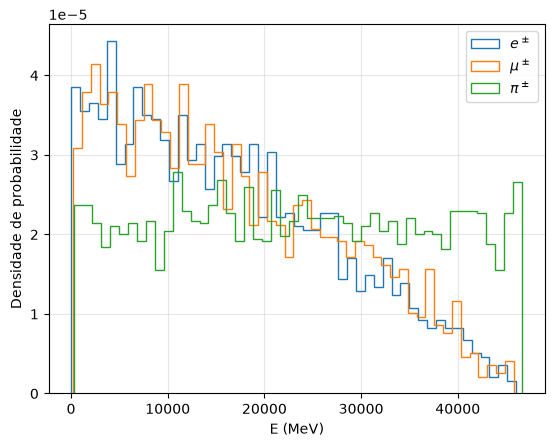

In [11]:
%%time
event_e = []
event_mu = []
event_pi = []
E_e = []; E_mu = []; E_pi = []

def E_espectro(data,event_number):
    dpars = data[data.event == event_number]
    pars = dpars.E.values
    return pars
    
for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'B+' or partic_ch == 'B-': # 1 electróns
        event_e.append(k)
        E_e.append(E_espectro(data,k)[0])
    elif partic_ch == 'C+' or partic_ch == 'C-': # 1 muóns
        event_mu.append(k)
        E_mu.append(E_espectro(data,k)[0])
    elif partic_ch == 'D+' or partic_ch == 'D-': # 1 pións
        event_pi.append(k)
        E_pi.append(E_espectro(data,k)[0])

plt.figure()
plt.hist(E_e, bins=50, histtype='step',
         density=True, label=r'$e^\pm$')

plt.hist(E_mu, bins=50, histtype='step',
         density=True, label=r'$\mu^\pm$')

plt.hist(E_pi, bins=50, histtype='step',
         density=True, label=r'$\pi^\pm$')

plt.xlabel('E (MeV)')
plt.ylabel('Densidade de probabilidade')
plt.legend()
plt.grid(alpha=0.3)

print(f'Eu non vexo ningunha diferenza apreciable entre as canles electrónicas das muónicas, as canles piónicas son practicamente equiprobables fronte as outras dúas que van decaendo')

sOLUCIÓNS redactadas nin idea lol

## 4. Calculad la distancia de vuelo del $\tau$ reconstruyendo su vértice de desintegración y estimad su vida media.

- Verificad que la masa invariante de los eventos con dos $\gamma$ corresponde a la masa de un $\pi^0$.
- Considerad que las partículas no están sometidas a un campo magnético y que sus trayectorias son líneas rectas.
- Utilizad los canales con 1 $\pi^0$ o con 3 piones cargados para obtener la distribución de la distancia de vuelo.
- ¿Es vuestra vida media compatible con la del PDG?
- En dichos canales, ¿podéis reconstruir el momento del $\nu_\tau$ que escapa sin detectar?


Agora pretendemos calcular a masa invariante dos eventos con 2$\gamma$ que son precisamente os eventos A+ e A-, logo se a masa invariante é o cadrado dos cadrimomentos imos ter o seguinte problema

$$ s = \mathbb{P}_\tau^2 = m_{\tau^\pm}^2 = \left(\sum_{productos} \mathbb{P}_i\right)^2 = \left(\mathbb{P}_{\pi^\pm} + \mathbb{P}_{\pi^0}\right)^2 = \left( \mathbb{P}_{\pi^\pm} + \mathbb{P}_{\gamma_1} + \mathbb{P}_{\gamma_2}\right)^2 \Rightarrow \mathbb{P}_{\pi^0}^2 = m^2_{\pi^0} = \left(\mathbb{P}_{\gamma_1} + \mathbb{P}_{\gamma_2}\right)^2 = (E_{\gamma_1} + E_{\gamma_2})^2 - |\vec p_{\gamma_1} + \vec p_{\gamma_2}|^2 $$

In [12]:
%%time
# Isto podemos traducilo a m_pi0 = (E1 + E2)**2 - (px1 + px2)**2 - (py1 + py2)**2 - (pz1 + pz2)**2.
# Primeiro saquemos os datos que son os das canles A+ e A-, tal que

def E_mom(data,event_number):
    dpars = data[data.event == event_number]
    gammas = dpars[dpars.particleName == 'gamma']
    Enerxias = gammas.E.values
    enx = gammas.px.values
    eny = gammas.py.values
    enz = gammas.pz.values
    return Enerxias, enx, eny, enz

n = int(s_ch[0]) # lembremos que xa calculei a extensións das canles

E_1 = np.zeros(n)
E_2 = np.zeros(n)
px1, py1, pz1 = np.zeros(n), np.zeros(n), np.zeros(n)
px2, py2, pz2 = np.zeros(n), np.zeros(n), np.zeros(n)

i = 0
for k in range(n_events):
    partic_ch = event_channel(data, k)
    if partic_ch == 'A+' or partic_ch == 'A-':
        E_1[i], E_2[i] = E_mom(data,k)[0]
        px1[i], px2[i] = E_mom(data,k)[1]
        py1[i], py2[i] = E_mom(data,k)[2]
        pz1[i], pz2[i] = E_mom(data,k)[3]
        i += 1

m_pi0 = np.zeros(n)
for k in range(n):
    m_pi0[k] = (E_1[k] + E_2[k])**2 - (px1[k] + px2[k])**2 - (py1[k] + py2[k])**2 - (pz1[k] + pz2[k])**2

m_pi0_media = np.sqrt(sum(m_pi0)/n)
print(f'A masa tabulada para o pion neutro é de 134.9766 MeV, no noso experimento podemos comparar o valor coa media da masa invariante obtida que é de {m_pi0_media:.4f}')

A masa tabulada para o pion neutro é de 134.9766 MeV, no noso experimento podemos comparar o valor coa media da masa invariante obtida que é de 134.9766
CPU times: total: 24 s
Wall time: 24.1 s


A masa que obtemos aquí para o pión neutro é idéntica á tabulada na Wikipedia o que nos serve de índice para asegurar que eses fotóns que observamos proveñen dun decaemento instantáneo do pión neutro

In [13]:
# Parte 4. Imos calcular a distancia de voo (L) dos tauons que é basicamente a distancia dende a orixe até onde se detectan partículas novas,
# i.e., coller o módulo das distancias que percorreron os productos de desintegración, logo promediala e xa temos unha distancia de voo media (<L>).
# Con isto preténdese medir o tempo de vida media que será <L> = v * <t>, pero non coñecemos a v dos tauons, pero si a enerxía que é de 45 GeV
# xogando un pouco coa relatividade especial: v = beta * c = c * np.sqrt(1 - 1/gamma**2) onde gamma = (E/m)_tauon pero tamén o tempo propio tense
# que tranformar segundo <t> = gamma * tau e así tau = <L>/(c*gamma*beta) que é o tempo de vida media

E_tau = 45 * 1000 # en MeV
m_tau = 1777 # MeV
c_luz = 3*10**8 # m/s
c_luz = c_luz * 1000 # en mm/s
gamma = E_tau/m_tau; beta = np.sqrt(1 - 1/gamma**2)

# nos nosos datos temos valores x,y,z que representan o punto do detector onde se mediron, temos tamén os momentos das partículas, se temos que
# P_tau = \Sum P_productos onde P_i é o cadrimomento o que temos é (45, p) = (sum(E_i), sum(p_i)) ==> p_tau = sum(p_i); fáltanos o momento dos 
# neutrinos que non se poden medir, podemos coller E_nu = |p_nu| porque m_nu = 0 e logo 45 - sum(E_i) = sum(E_nu) = sum(|p_nu|)

<L> = 1.7477828875751962 mm
<tau> = 2.3023959883333385e-13 s
CPU times: total: 15.1 s
Wall time: 15.1 s


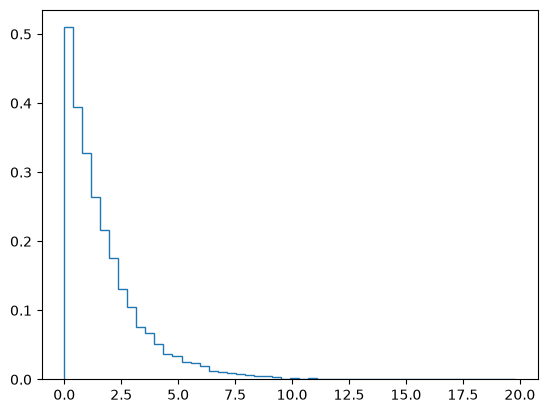

In [14]:
%%time
def reconstruct_vertex(evt): # programa de IA porque eu nin puta idea e non teño tanto tempo

    A = np.zeros((3,3))
    b = np.zeros(3)

    for _, row in evt.iterrows():
        r = np.array([row.x,row.y,row.z])
        p = np.array([row.px,row.py,row.pz])
        u = p/np.linalg.norm(p)

        Ai = np.eye(3) - np.outer(u,u)
        A += Ai
        b += Ai @ r

    v = np.linalg.solve(A,b)
    return v

L = []; eventos_validos = 0
for k in range(n_events):
    partic_ch = event_channel(data, k) # o enunciado indica que usemos os canais cun pion neutro ou 3 pions cargados que son os A e F, engado E porque ten 2 pion0 decaendo en 4 fotons, só aparece un neutrino, que é o taunico
    if partic_ch == 'A+' or partic_ch == 'A-' or partic_ch == 'E+' or partic_ch == 'E-' or partic_ch == 'F+' or partic_ch == 'F-':
        evt = data[data.event == k]
        v = reconstruct_vertex(evt)
        L.append(np.linalg.norm(v))

plt.figure(); plt.hist(L, bins=50, histtype='step', density=True, label=r'L [mm]')

L_medi = sum(L)/len(L)
print(f'<L> = {L_medi} mm')
tau_m = L_medi/(c_luz*beta*gamma)
print(f'<tau> = {tau_m} s')

In [15]:
# Unha mellor estimación pode ser lograda aplicando un axuste sobre a lei de desintegración

from scipy.optimize import curve_fit

def exp(L, A, ell): # ell == L media
    return A*np.exp(-L/ell)

counts, bins = np.histogram(L, bins=50)
centers = 0.5*(bins[1:] + bins[:-1])

popt, pcov = curve_fit(exp, centers, counts, p0 = [counts.max(), L_medi])
A_axustado, ell_axustado = popt
sA, sell = np.sqrt(np.diag(pcov))

tau_m = ell_axustado/(c_luz*beta*gamma)
stau = sell/(c_luz*beta*gamma)
print(f'o tempo de vida media é <tau> = {tau_m*10**15:.4} +- {stau*10**15:.2} fs')

o tempo de vida media é <tau> = 233.9 +- 1.9 fs


Lembremos que os nosos datos non son de todo reais, hai parámetros modificados

Por último hai que medir o momento dos neutrinos invisibles. Para iso, por conservación do cudrimomento

$$\mathbb{P}_{\tau} = \sum \mathbb{P}_{\text{visibles}} + \sum \mathbb{P}_{\nu_i}$$

simplificamos o problema a só aquelas canles (A, E, F) onde se escapa un único neutrino que é o tauónico, logo

$$\mathbb{P}_{\tau} = \sum \mathbb{P}_{\text{visibles}} + \mathbb{P}_{\nu_\tau} \Rightarrow (E_\tau, \vec p_\tau) = (E_{\text{visibles}} + E_{\nu_\tau},\  \vec p_{\text{visibles}} + \vec p_{\nu_\tau})$$
Logo
$$E_\nu = E_\tau - E_{\text{visibles}};\ \ \ \vec p_\nu = \vec p_\tau - \vec p_{\text{visibles}}$$
que ademais como $m_nu = 0$ temos que $E_\nu = |\vec p_\nu|$

In [16]:
%%time
# definimos antes E_tau e m_tau. As canles que só teñen un neutrino son a A, E e F
# por invarianza da norma do cadrimomento m_tau^2 = E_tau^2 - p_tau^2 ==> |p_tau| = sqrt(E_tau^2 - m_tau^2)

modulo_tau = np.sqrt(E_tau**2 - m_tau**2)
# a dirección que leva o tauon a reconstruímos antes cando calculamos o vértice, é o unitario da posición de V

errores = 0
neutrino = namedtuple('P_nu', ('E', 'p'))
for k in range(n_events):
    partic_ch = event_channel(data, k) # o enunciado indica que usemos os canais cun pion neutro ou 3 pions cargados que son os A e F, engado E porque ten 2 pion0 decaendo en 4 fotons, só aparece un neutrino, que é o taunico
    if partic_ch == 'A+' or partic_ch == 'A-' or partic_ch == 'E+' or partic_ch == 'E-' or partic_ch == 'F+' or partic_ch == 'F-':
        event_nu = data[data.event == k]
        V = reconstruct_vertex(event_nu)
        u_tau = V/np.linalg.norm(V)
        p_tau = modulo_tau * u_tau
        px_visible = sum(event_nu.px.values); py_visible = sum(event_nu.py.values); pz_visible = sum(event_nu.pz.values)
        pxnu = p_tau[0] - px_visible; pynu = p_tau[1] - py_visible; pznu = p_tau[2] - pz_visible
        p_nu = (pxnu,pynu,pznu)

        E_visible = sum(event_nu.E.values)
        E_nu = E_tau - E_visible
        print(neutrino(E_nu, p_nu))

        if E_nu<0:
            print(f'No evento número {k} resulta unha enerxía negativa para o neutrino, logo as partículas detectadas teñen máis enerxía que o tauon do que proveñen')
            print(data[data.event == k])
            errores += 1

print(f'hai un total de {errores} eventos con enerxía imposibles, salvo que non todos os tauons tiveran 45 GeV')

P_nu(E=950.5785096494801, p=(615.4140711270302, 678.2562182046167, 294.66850886409156))
P_nu(E=26444.317427810987, p=(-19364.52064420464, 417.61253362755167, -18002.136636829156))
P_nu(E=12958.78605201342, p=(-7010.660802970588, 3167.9848342567184, -10428.952649664643))
P_nu(E=2861.956671226333, p=(1224.2233718076186, -989.5789719977947, -2402.6839261803398))
P_nu(E=10041.10798647102, p=(3790.440081812567, 5823.501354492644, -7249.477192028749))
P_nu(E=32001.291341811826, p=(6980.840844252343, 24095.896153985064, 19866.301848904714))
P_nu(E=-584.264273761255, p=(-576.1030821498935, -172.85723969226456, 118.32635030419351))
No evento número 12 resulta unha enerxía negativa para o neutrino, logo as partículas detectadas teñen máis enerxía que o tauon do que proveñen
    event particleName          x          y         z            px  \
26     12          pi+  42.973007  25.294007 -3.678845  13629.169921   
27     12          pi+  43.981382  23.332685 -4.606935  19725.683302   
28     12

## 5. Universalidad leptónica. En vuestro universo el $\tau$ se acopla al $W$ exactamente igual que el $\mu$ y el $e$. A partir de vuestra fracción $B(\tau^- \to e^- \bar\nu_e \nu_\tau)$, de la vida media del muón y de las masas del $\mu$ y del $\tau$, predecid la vida media del $\tau$ y comparadla con la que habéis medido en el apartado 4.

O primeiro é cargar a fracción da canle que calculamos no punto 2, as canles monoelectrónicas son as B+ e B- e as muónicos C+ e C-, e as masas e tempos de vida media do $e^+$ e do $\mu^+$.

In [17]:
# os nosos valores para t_tau foron tau_m \pm stau
m_e = 0.511 # MeV
m_mu = 105.66 # MeV
t_e = 4.6 * 3600 * 24 * 365 * 10**26 # "El límite inferior experimental de la vida media de un electrón es de 4,6 × 10^26 años" segundo a wikipedia
t_mu = 2.2 * 10**(-6)
Br_e = float(s_ch[1])/n_events
Br_mu = float(s_ch[2])/n_events

Dos apuntamentos considerando que os tres leptóns acóplanse exactamente igual ao bosón ($g^\tau_W = g^\mu_W = g^e_W = g_W$) e $\mathcal{Br}(\mu\to e + \bar\nu_e +\nu_\mu)$ = 1
$$\Gamma (\mu\to e + \bar\nu_e +\nu_\mu) = \frac{1}{\tau_\mu} = \frac{G_F^2m_\mu^5}{192\pi^3} \Rightarrow \frac{G_F^2}{192\pi^3} = \frac{1}{m_\mu^5\tau_\mu} $$
$$\Gamma (\tau\to e + \bar\nu_e +\nu_\tau) = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{\tau_\tau} = \frac{G_F^2m_\tau^5}{192\pi^3} \Rightarrow \frac{G_F^2}{192\pi^3} = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{m_\tau^5\tau_\tau}$$
$$\Rightarrow \frac{1}{m_\mu^5\tau_\mu} = \frac{\mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau)}{m_\tau^5\tau_\tau} \Rightarrow \tau_\tau = \tau_\mu \left(\frac{m_\mu}{m_\tau}\right)^5 \mathcal{Br}(\tau\to e + \bar\nu_e +\nu_\tau) $$

In [19]:
t_tau = t_mu * (m_mu/m_tau)**5 * Br_e
print(f'A vida media estimada polo acoplo para o tauón é de {t_tau*10**15:.4} fs, fronte aos {tau_m*10**15:.4} +- {stau*10**15:.2} fs estimados coa distanci de voo dos tauóns')

A vida media estimada polo acoplo para o tauón é de 215.2 fs, fronte aos 233.9 +- 1.9 fs estimados coa distanci de voo dos tauóns


## Por que?
Lembremos tamén que a real é da orde de 290 fs e nós temos 230 fs porque o noso universo non é exactamente o universo real. Onde pode aparecer o erro?

O seguinte código era o que nos servía para calcular as rectas de reconstrucción do vértice e eu preguntándolle á IA......

In [ ]:
import scipy.linalg as la
def intersection_of_straight_lines(x1, v1, x2, v2):
    """ compute the instersection point of two straight lines

    Inputs:
        x1: tuple or np.array, reference point of line 1
        v1: tuple or np.array, direction vector of line 1
        x1: tuple or np.array, reference point of line 1
        v1: tuple or np.array, direction vector of line 1

    Returns:
        x: np.array, the closest point of line 1 to the intersection
                     the intersection point if both lines really intersect

    Algorithm:
        Intersection of two straight lines:
            x1(t) = x1 + t1 * v1
            x2(t) = x2 + t2 * v2,
        where x1 is a point in the line 1 and v1 is the direction vector (i.e momentum), and t1 is the running parameter.
        x1, v2, t2 the same for line 2. 
        
        condition: x1(t) = x2(t) => x2- x1 = t1 * v1 - t2 * v2
        solve the equations and estimate the two scalars: t1 and t2 
    """


    x1 = np.array(x1)
    x2 = np.array(x2)
    v1 = np.array(v1)
    v2 = np.array(v2)

    bb = x2 - x1
    ndim = len(bb)
    aa = np.zeros((ndim, 2))
    aa[:, 0] =  v1
    aa[:, 1] = -v2

    tt = la.lstsq(aa, bb)[0]
    x1i = x1 + tt[0] * v1
    return x1i


In [63]:
def event_channel(data, event_number):
    edata = data[data.event == event_number] ## get the particles of the event
    pars  = list(edata.particleName) ## get the names of the particles 
    pars.sort()
    return pars
    
n_events = max(data['event']) + 1 # total de eventos

for i in range(n_events):
    print(event_channel(data,i))

['pi-']
['pi+']
['pi+', 'pi-', 'pi-']
['pi-']
['pi-']
['gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'pi-']
['e-']
['pi+', 'pi-', 'pi-']
['gamma', 'gamma', 'gamma', 'gamma', 'pi-']
['pi+']
['pi+', 'pi-', 'pi-']
['pi+', 'pi+', 'pi-']
['e+']
['pi+', 'pi-', 'pi-']
['gamma', 'gamma', 'gamma', 'gamma', 'pi+']
['pi+', 'pi-', 'pi-']
['gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'pi+']
['e-']
['gamma', 'gamma', 'pi+']
['mu+']
['gamma', 'gamma', 'gamma', 'gamma', 'pi-']
['mu-']
['gamma', 'gamma', 'pi+']
['gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'gamma', 'gamma', 'pi-']
['pi-']
['pi+', 'pi-', 'pi-']
['mu-']
['pi+', 'pi-', 'pi-']
['gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'gamma', 'gamma', 'pi-']
['pi+']
['pi+']
['gamma', 'gamma', 'pi-']
['e+']
['pi-']
['gamma', 'gamma', 'gamma', 'gamma', 'pi+']
['e-']
['pi+', 'pi-', 'pi-']
['mu+']
['gamma', 'gamma', 'gamma', 'gamma', 'pi-']
['gamma', 'gamma', 'pi-']
['pi+']
['gamma', 'gamma', 'gamma', 'gamma', 'pi+']
['mu+']
['pi-']
[